<a href="https://colab.research.google.com/github/dmtzsegura/actividades-tareas/blob/master/aprendizaje-maquina/Lab8_Netflix_Churn_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 8: Predicción de cancelación de clientes (Churn) en Netflix
**Alumna:** Daniela Martínez Segura | **Matrícula:** 2503036
**Materia:** Aprendizaje de Máquina

**Objetivo:** construir un pipeline de procesamiento y entrenamiento que prediga si un cliente cancelará su suscripción (`churned`: 0 = activo, 1 = canceló).

**Dataset:** [Netflix Customer Churn & Engagement Analytics](https://www.kaggle.com/datasets/zeyadmohamed26/netflix-customer-churn-and-engagement-analytics) (Kaggle, licencia CC0).
⚠️ Es un dataset **sintético** con fines educativos. No contiene datos reales de Netflix.

In [1]:
# Importamos pandas, la librería para trabajar con tablas (DataFrames)
import pandas as pd

# Link "raw" (archivo crudo) del CSV en tu repo de GitHub
url = "https://raw.githubusercontent.com/dmtzsegura/actividades-tareas/master/aprendizaje-maquina/netflix_customer_churn.csv"

# Leemos el CSV y lo guardamos en la variable df
df = pd.read_csv(url)

# Mostramos el tamaño (filas, columnas)
print("Tamaño del dataset:", df.shape)

# Mostramos las primeras 5 filas
df.head()

Tamaño del dataset: (5000, 14)


,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


### Conclusión: carga de datos
El dataset se cargó correctamente desde GitHub. Tiene **5,000 clientes (filas)** y **14 columnas**, entre ellas datos demográficos (edad, género, región), de suscripción (tipo de plan, cuota mensual, método de pago) y de uso (horas vistas, días desde el último inicio de sesión). La columna objetivo es `churned`.

In [2]:
# 1) Tipos de dato de cada columna (int/float = número, object = texto)
print("=== Tipos de dato ===")
print(df.dtypes)

# 2) Cantidad de valores nulos (vacíos) por columna
print("\n=== Valores nulos ===")
print(df.isnull().sum())

# 3) Cantidad de filas duplicadas
print("\n=== Filas duplicadas ===")
print(df.duplicated().sum())

# 4) Balance de la variable objetivo, en porcentaje
print("\n=== Balance de churned (%) ===")
print(df["churned"].value_counts(normalize=True) * 100)

=== Tipos de dato ===
customer_id                object
age                         int64
gender                     object
subscription_type          object
watch_hours               float64
last_login_days             int64
region                     object
device                     object
monthly_fee               float64
churned                     int64
payment_method             object
number_of_profiles          int64
avg_watch_time_per_day    float64
favorite_genre             object
dtype: object

=== Valores nulos ===
customer_id               0
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
churned                   0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0
dtype: int64

=== Filas duplicadas ===
0

=== Balance de churned (%) ===


### Conclusión: calidad de los datos
- El dataset **no tiene valores nulos ni filas duplicadas**.
- Hay **6 variables numéricas** y **6 categóricas (texto)**. Las categóricas deberán codificarse a números.
- `customer_id` es solo un identificador único, por lo que se eliminará al no aportar información para predecir.
- La variable objetivo está **balanceada** (50.3% canceló y 49.7% sigue activo), así que no es necesario aplicar técnicas de balanceo de clases.

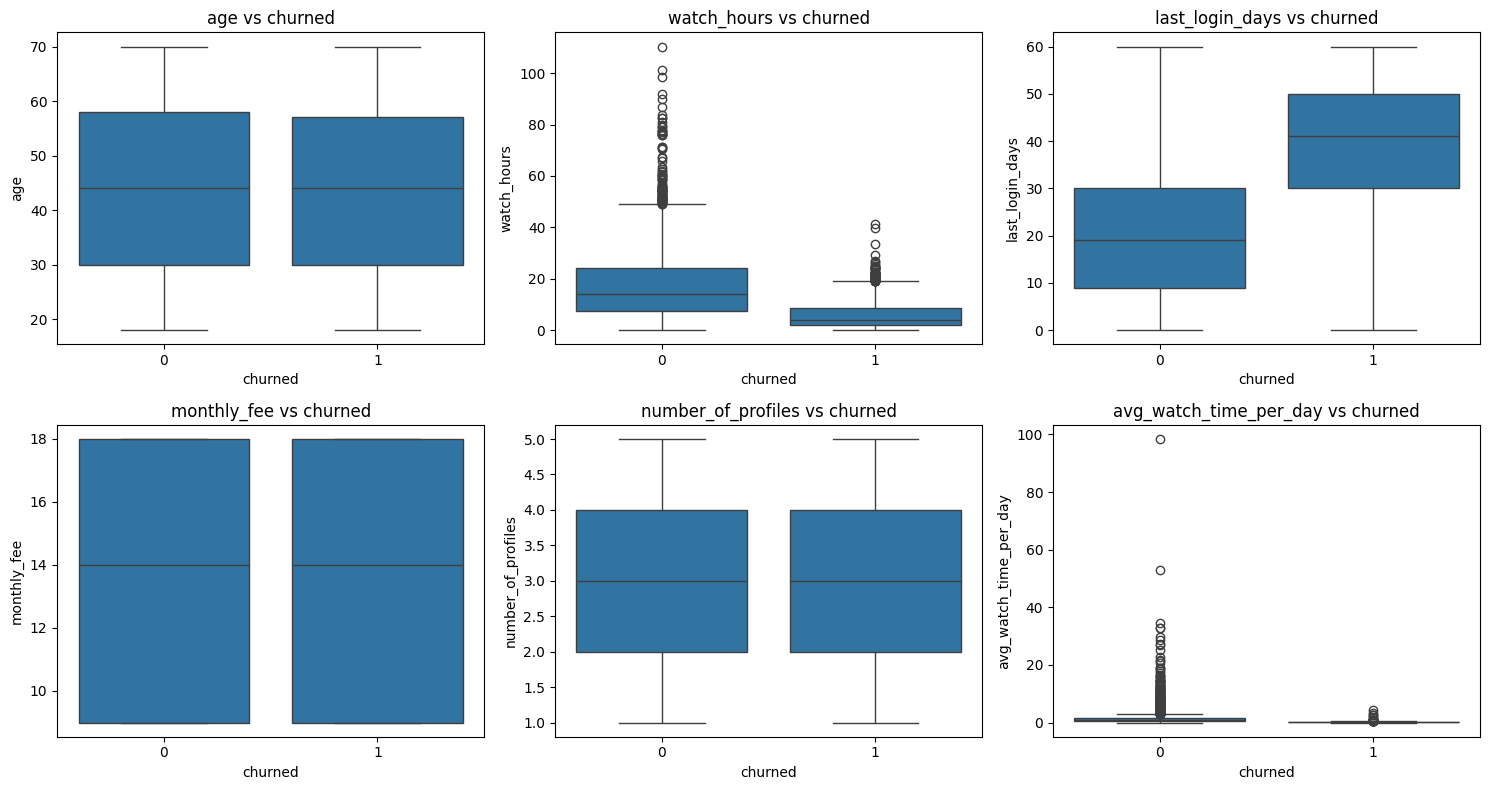

=== Promedios por grupo ===
           age  watch_hours  last_login_days  monthly_fee  number_of_profiles  \
churned                                                                         
0        43.90        17.45            21.77        14.25                3.25   
1        43.79         5.92            38.31        13.13                2.80   

         avg_watch_time_per_day  
churned                          
0                          1.59  
1                          0.16  


In [3]:
# Librerías para gráficas
import matplotlib.pyplot as plt
import seaborn as sns

# Lista de columnas numéricas (sin churned, que es lo que queremos predecir)
numericas = ["age", "watch_hours", "last_login_days", "monthly_fee",
             "number_of_profiles", "avg_watch_time_per_day"]

# Creamos una cuadrícula de 2 filas x 3 columnas de gráficas
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Dibujamos un boxplot por cada variable, separado por churned
for ax, col in zip(axes.flatten(), numericas):
    sns.boxplot(data=df, x="churned", y=col, ax=ax)
    ax.set_title(f"{col} vs churned")

plt.tight_layout()
plt.show()

# Promedio de cada variable en cada grupo (0 = activo, 1 = canceló)
print("=== Promedios por grupo ===")
print(df.groupby("churned")[numericas].mean().round(2))

### Conclusión: variables numéricas
- Las variables de **uso de la plataforma** son las más relacionadas con la cancelación. Los clientes que cancelaron vieron en promedio **5.9 horas** contra **17.5** de los activos, tienen un tiempo diario de **0.16 h** contra **1.59 h**, y llevan **38 días** sin iniciar sesión contra **22**.
- Quienes cancelan pagan una cuota ligeramente menor (planes más económicos) y tienen menos perfiles en su cuenta.
- La **edad** casi no cambia entre grupos (~44 años), por lo que su poder predictivo parece bajo.
- **Interpretación de negocio:** un cliente que deja de usar la plataforma está en riesgo de cancelar. Detectar la caída de actividad a tiempo permitiría lanzar campañas de retención.

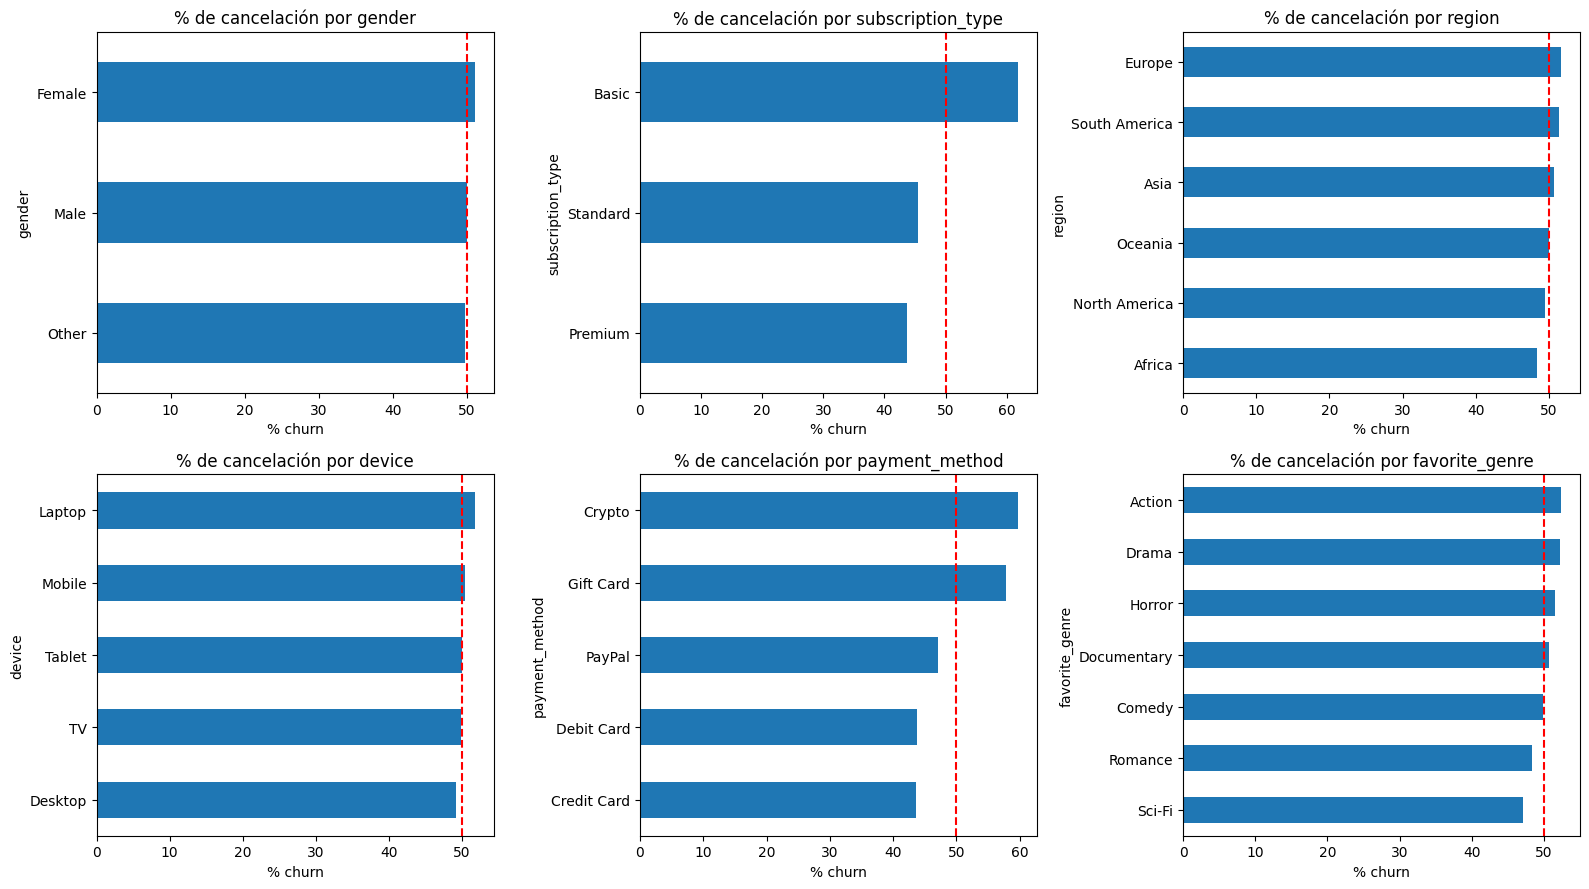


=== gender ===
gender
Other     49.8
Male      50.0
Female    51.1
Name: churned, dtype: float64

=== subscription_type ===
subscription_type
Premium     43.7
Standard    45.4
Basic       61.8
Name: churned, dtype: float64

=== region ===
region
Africa           48.3
North America    49.5
Oceania          50.1
Asia             50.7
South America    51.4
Europe           51.7
Name: churned, dtype: float64

=== device ===
device
Desktop    49.2
TV         49.9
Tablet     50.0
Mobile     50.5
Laptop     51.8
Name: churned, dtype: float64

=== payment_method ===
payment_method
Credit Card    43.6
Debit Card     43.7
PayPal         47.1
Gift Card      57.8
Crypto         59.7
Name: churned, dtype: float64

=== favorite_genre ===
favorite_genre
Sci-Fi         47.1
Romance        48.3
Comedy         49.9
Documentary    50.8
Horror         51.5
Drama          52.3
Action         52.4
Name: churned, dtype: float64


In [4]:
# Lista de columnas categóricas (texto), sin customer_id
categoricas = ["gender", "subscription_type", "region", "device",
               "payment_method", "favorite_genre"]

# Cuadrícula de 2 filas x 3 columnas de gráficas
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flatten(), categoricas):
    # Promedio de churned por categoría = % de cancelación (x100)
    tasa = df.groupby(col)["churned"].mean().sort_values() * 100
    tasa.plot(kind="barh", ax=ax)          # barras horizontales
    ax.axvline(50, color="red", ls="--")   # línea del 50% general
    ax.set_title(f"% de cancelación por {col}")
    ax.set_xlabel("% churn")

plt.tight_layout()
plt.show()

# Tabla con los porcentajes, para leerlos con precisión
for col in categoricas:
    print(f"\n=== {col} ===")
    print((df.groupby(col)["churned"].mean() * 100).round(1).sort_values())

### Conclusión: variables categóricas
- **Tipo de suscripción:** el plan **Basic** tiene la mayor tasa de cancelación (**61.8%**), contra ~44-45% de Standard y Premium.
- **Método de pago:** los clientes que pagan con **Crypto (59.7%)** o **Gift Card (57.8%)** cancelan más que los que pagan con tarjeta de crédito o débito (~44%). Una posible explicación es que la tarjeta permite cobros recurrentes automáticos, mientras que los otros métodos obligan al cliente a renovar manualmente.
- **Género, región, dispositivo y género favorito** se mantienen cerca del 50%, por lo que su poder predictivo parece bajo.
- Se conservarán todas las variables en el modelo y se validará su importancia al final.

In [5]:
import numpy as np

def crear_variables(X):
    """Recibe un DataFrame y regresa una copia con 3 variables nuevas."""
    X = X.copy()  # copia para no modificar los datos originales

    # 1 si paga con tarjeta (cobro automático), 0 si no
    X["pago_recurrente"] = X["payment_method"].isin(["Credit Card", "Debit Card"]).astype(int)

    # Horas vistas por perfil (replace evita dividir entre 0)
    X["horas_por_perfil"] = X["watch_hours"] / X["number_of_profiles"].replace(0, np.nan)
    X["horas_por_perfil"] = X["horas_por_perfil"].fillna(0)

    # 1 si lleva más de 30 días sin iniciar sesión
    X["inactivo_30"] = (X["last_login_days"] > 30).astype(int)

    return X

# Probamos la función y revisamos el % de cancelación en las nuevas variables binarias
prueba = crear_variables(df)
print(prueba[["pago_recurrente", "horas_por_perfil", "inactivo_30"]].head())
print("\n% churn por pago_recurrente:\n", (prueba.groupby("pago_recurrente")["churned"].mean()*100).round(1))
print("\n% churn por inactivo_30:\n", (prueba.groupby("inactivo_30")["churned"].mean()*100).round(1))

   pago_recurrente  horas_por_perfil  inactivo_30
0                0            14.730            0
1                0             0.140            0
2                0             8.160            0
3                0             2.255            0
4                0             0.945            0

% churn por pago_recurrente:
 pago_recurrente
0    54.8
1    43.6
Name: churned, dtype: float64

% churn por inactivo_30:
 inactivo_30
0    26.1
1    75.1
Name: churned, dtype: float64


### Conclusión: feature engineering
Se crearon 3 variables nuevas con base en los hallazgos del análisis exploratorio:
- **`inactivo_30`** (más de 30 días sin iniciar sesión): es la más reveladora. Los clientes inactivos cancelan en un **75.1%**, contra **26.1%** de los activos.
- **`pago_recurrente`** (paga con tarjeta): estos clientes cancelan menos (**43.6%** contra **54.8%**).
- **`horas_por_perfil`**: mide el consumo real por persona dentro de la cuenta.

Las transformaciones se encapsularon en la función `crear_variables`, que se integrará al pipeline. Así se aplicarán automáticamente a cualquier dato nuevo.